In [1]:
import os
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nDoes the relative data folder exist?")
print(Path("data/processed/signals").exists())

print("\nFiles in the current directory:")
print(os.listdir())

Current working directory:
d:\IITK_Assignments\CS724\Project

Does the relative data folder exist?
True

Files in the current directory:
['.venv', '02_csi_preprocessing.ipynb', 'data', 'src']


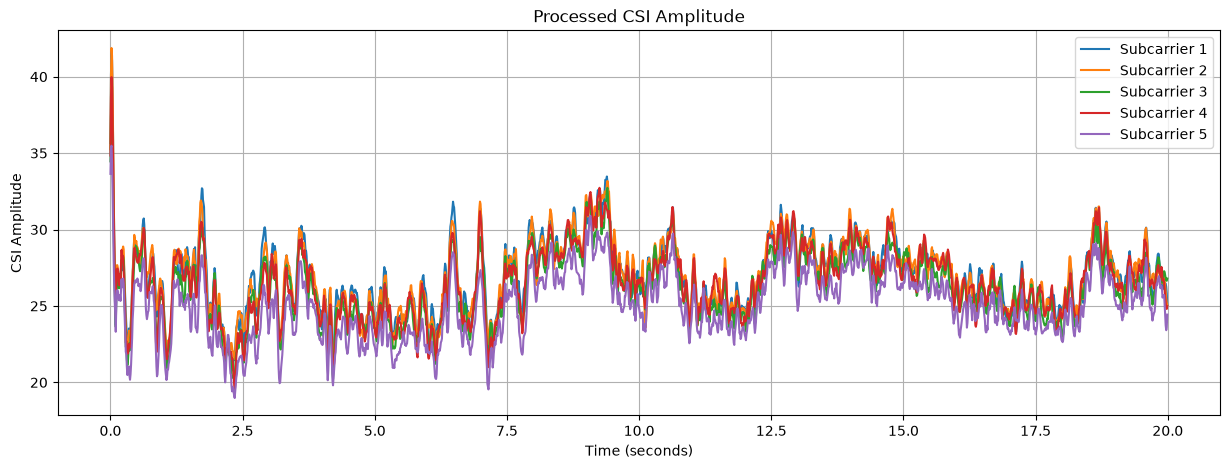

Shape: (2000, 52)
Minimum: 7.4716563
Maximum: 41.875267
Mean: 17.597866
Standard deviation: 4.579457


In [2]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load(
    "data/processed/signals/P00_A01_R1_1790671306.npy"
)

time = np.arange(2000) / 100

plt.figure(figsize=(15, 5))

for i in range(5):
    plt.plot(
        time,
        data[:, i],
        label=f"Subcarrier {i+1}"
    )

plt.xlabel("Time (seconds)")
plt.ylabel("CSI Amplitude")
plt.title("Processed CSI Amplitude")

plt.legend()
plt.grid()
plt.show()

print("Shape:", data.shape)
print("Minimum:", data.min())
print("Maximum:", data.max())
print("Mean:", data.mean())
print("Standard deviation:", data.std())

In [8]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
metadata = pd.read_csv(PROJECT_ROOT / "data/processed/metadata.csv")

print("Processed recordings:", len(metadata))
print("\nRecording types:")
print(metadata["recording_type"].value_counts())

print("\nLocations:")
print(metadata["location"].value_counts())

# Inspect the raw string stored in the CSV
raw_path = Path(metadata.iloc[0]["processed_file"])
print("\nStored path in CSV:", raw_path)

# Fix path resolution regardless of whether it was saved relative to Project/ or from Colab/another PC
if raw_path.exists():
    sample_path = raw_path
elif (PROJECT_ROOT / raw_path).exists():
    sample_path = PROJECT_ROOT / raw_path
else:
    # Fallback: match by filename inside Project/data/processed/signals/
    sample_path = PROJECT_ROOT / "data/processed/signals" / raw_path.name

sample = np.load(sample_path)
print("Resolved path:", sample_path)
print("Sample shape:", sample.shape)


Processed recordings: 308

Recording types:
recording_type
activity    308
Name: count, dtype: int64

Locations:
location
Location_2    110
Location_1    107
Location_3     91
Name: count, dtype: int64

Stored path in CSV: data\processed\signals\P00_A01_R1_1790671306.npy
Resolved path: D:\IITK_Assignments\CS724\Project\data\processed\signals\P00_A01_R1_1790671306.npy
Sample shape: (2000, 52)


In [10]:
import pandas as pd

errors = pd.read_csv("../data/processed/preprocessing_errors.csv")

print("Total failed:", len(errors))

print("\nMost common errors:")
print(errors["error"].value_counts().head(20))

print("\nFirst 15 failed recordings:")
print(errors[["raw_file", "error"]].head(15).to_string(index=False))

Total failed: 344

Most common errors:
error
string or file could not be read to its end due to unmatched data      253
Large packet gap detected.                                              16
Filename does not match expected format: P00_BASE_R1_1790670063.csv      1
Filename does not match expected format: P00_BASE_R2_1790670734.csv      1
Filename does not match expected format: P01_BASE_R1_1790675066.csv      1
Filename does not match expected format: P01_BASE_R2_1790675921.csv      1
Filename does not match expected format: P02_BASE_R1_1790676738.csv      1
Filename does not match expected format: P02_BASE_R2_1790677382.csv      1
Filename does not match expected format: P03_BASE_R1_1790678541.csv      1
Filename does not match expected format: P03_BASE_R2_1790679084.csv      1
Filename does not match expected format: P04_BASE_R1_1790679751.csv      1
Filename does not match expected format: P04_BASE_R2_1790680321.csv      1
Filename does not match expected format: P05_BASE_R1_17

In [11]:
import re

def get_activity(path):
    match = re.search(r"_A(\d+)_", str(path))
    return int(match.group(1)) if match else None

def get_participant(path):
    match = re.search(r"(P\d+)", str(path))
    return match.group(1) if match else None

errors["activity"] = errors["raw_file"].apply(get_activity)
errors["participant"] = errors["raw_file"].apply(get_participant)

print("Failures by activity:")
print(errors["activity"].value_counts().sort_index())

print("\nFailures by participant:")
print(errors["participant"].value_counts().sort_index())

Failures by activity:
activity
1.0     10
2.0     12
3.0     17
4.0     11
5.0     17
6.0     14
7.0     18
8.0     14
9.0     13
10.0     8
11.0    12
12.0    13
13.0    13
14.0    16
15.0    15
16.0    11
17.0    10
18.0    15
19.0    15
20.0    15
Name: count, dtype: int64

Failures by participant:
participant
P00     9
P01    10
P02    11
P03    12
P04    14
P05    15
P06    18
P07    14
P08    15
P09     9
P10     9
P11    14
P12    10
P13     9
P14     5
P15    11
P16    11
P17    12
P18    14
P19    11
P20    11
P21    11
P22    11
P23    15
P24    15
P25    14
P26    16
P27    18
Name: count, dtype: int64


In [ ]:
#Testing the parser to support both name formats: P00_A01_R1_1790671306 and P00_BASE_R1_1790671306

import sys
from pathlib import Path
import pandas as pd

# 1. Add the Project root folder (one level up from notebooks/) to Python's path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 2. Import directly from src (without 'Project.')
from src.preprocessing import parse_csi_line

test_file = PROJECT_ROOT / "data/data/P01/P01_A10_R1_1790675504.csv"

# test_file = Path("../data/data/P01/P01_A10_R1_1790675504.csv")


df = pd.read_csv(test_file)

valid_arrays = [
    parse_csi_line(line)
    for line in df["csi_line"]
]

valid_count = sum(x is not None for x in valid_arrays)

print("Total packets:", len(df))
print("Valid CSI packets:", valid_count)
print("Invalid CSI packets:", len(df) - valid_count)

Total packets: 2231
Valid CSI packets: 2230
Invalid CSI packets: 1


In [ ]:
# Checking the large packet gap errors in the preprocessing_errors.csv file

from pathlib import Path
import pandas as pd
import numpy as np

# Step out of 'notebooks/' into 'Project/'
PROJECT_ROOT = Path("..").resolve()

gap_errors = errors[
    errors["error"].str.contains(
        "Large packet gap detected",
        na=False
    )
]

for _, row in gap_errors.iterrows():

    file_path = PROJECT_ROOT / row["raw_file"]

    df = pd.read_csv(file_path)

    valid = df["csi_line"].apply(
        lambda x: parse_csi_line(x) is not None
    )

    timestamps = (
        df.loc[valid, "timestamp"]
        .astype(float)
        .sort_values()
        .to_numpy()
    )

    intervals = np.diff(timestamps)

    print("\nFile:", file_path.name)
    print("Valid packets:", len(timestamps))
    print("Duration:", round(timestamps[-1] - timestamps[0], 3))
    print("Maximum gap:", round(intervals.max(), 4), "seconds")



File: P03_A17_R1_1790679017.csv
Valid packets: 2232
Duration: 21.997
Maximum gap: 0.104 seconds

File: P04_A18_R1_1790680759.csv
Valid packets: 2235
Duration: 22.001
Maximum gap: 0.1065 seconds

File: P08_A03_R1_1790685867.csv
Valid packets: 2234
Duration: 22.008
Maximum gap: 0.1228 seconds

File: P08_A10_R1_1790686004.csv
Valid packets: 2203
Duration: 22.005
Maximum gap: 0.1135 seconds

File: P08_A20_R1_1790685293.csv
Valid packets: 2210
Duration: 21.999
Maximum gap: 0.1119 seconds

File: P11_A05_R1_1794049828.csv
Valid packets: 2205
Duration: 21.997
Maximum gap: 0.1052 seconds

File: P11_A10_R1_1794050135.csv
Valid packets: 2161
Duration: 22.0
Maximum gap: 0.1804 seconds

File: P12_A17_R1_1794051640.csv
Valid packets: 2106
Duration: 22.005
Maximum gap: 0.1574 seconds

File: P14_A11_R1_1794053577.csv
Valid packets: 2244
Duration: 22.003
Maximum gap: 0.1331 seconds

File: P18_A03_R1_1794057304.csv
Valid packets: 2229
Duration: 22.004
Maximum gap: 0.1434 seconds

File: P18_A14_R1_17940

In [21]:
#Testing the new batch_preprocessing code

import pandas as pd

metadata = pd.read_csv("../data/processed/metadata.csv")
errors = pd.read_csv("../data/processed/preprocessing_errors.csv")

print("Successful:", len(metadata))
print("Failed:", len(errors))

print("\nRecording types:")
print(metadata["recording_type"].value_counts())

print("\nLocations:")
print(metadata["location"].value_counts())

print("\nRemaining errors:")
print(errors["error"].value_counts().head(20))

Successful: 620
Failed: 32

Recording types:
recording_type
activity    548
baseline     72
Name: count, dtype: int64

Locations:
location
Location_1    226
Location_3    200
Location_2    194
Name: count, dtype: int64

Remaining errors:
error
Large packet gap detected.    32
Name: count, dtype: int64


In [22]:
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
bad_files = []

for _, row in metadata.iterrows():
    # Resolve path relative to Project/ instead of notebooks/
    raw_path = Path(str(row["processed_file"]).replace("\\", "/"))
    file_path = raw_path if raw_path.is_absolute() else PROJECT_ROOT / raw_path

    if not file_path.exists():
        bad_files.append((row["recording_id"], "File not found"))
        continue

    signal = np.load(file_path)

    if signal.shape != (2000, 52):
        bad_files.append((row["recording_id"], f"Wrong shape: {signal.shape}"))

    elif not np.isfinite(signal).all():
        bad_files.append((row["recording_id"], "Non-finite values"))

print("Invalid processed files:", len(bad_files))
print(bad_files[:10])


Invalid processed files: 0
[]


In [23]:
#Identifying the 6 failed recordings

import pandas as pd

errors = pd.read_csv("../data/processed/preprocessing_errors.csv")

print("Remaining failed recordings:")
print(errors[["raw_file", "error"]].to_string(index=False))

print("\nError categories:")
print(errors["error"].value_counts())

Remaining failed recordings:
                               raw_file                      error
data\data\P11\P11_A10_R1_1794050135.csv Large packet gap detected.
data\data\P12\P12_A17_R1_1794051640.csv Large packet gap detected.
data\data\P26\P26_A10_R1_1794407243.csv Large packet gap detected.
data\data\P26\P26_A18_R1_1794407419.csv Large packet gap detected.
data\data\P27\P27_A16_R1_1794408159.csv Large packet gap detected.
data\data\P27\P27_A19_R1_1794408319.csv Large packet gap detected.

Error categories:
error
Large packet gap detected.    6
Name: count, dtype: int64


In [ ]:
#Which participants and acitivities failed

import re

errors["participant"] = errors["raw_file"].str.extract(r"(P\d+)")
errors["activity"] = errors["raw_file"].str.extract(r"_A(\d+)_")

print("Failures by participant:")
print(errors["participant"].value_counts().sort_index())

print("\nFailures by activity:")
print(errors["activity"].value_counts().sort_index())

Failures by participant:
participant
P11    1
P12    1
P26    2
P27    2
Name: count, dtype: int64

Failures by activity:
activity
10    2
16    1
17    1
18    1
19    1
Name: count, dtype: int64


In [29]:
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
bad_files = []

for _, row in metadata.iterrows():
    file_path = PROJECT_ROOT / str(row["processed_file"]).replace("\\", "/")
    signal = np.load(file_path)

    if signal.shape != (2000, 52):
        bad_files.append((row["recording_id"], "Wrong shape"))

    elif not np.isfinite(signal).all():
        bad_files.append((row["recording_id"], "Non-finite values"))

print("Invalid processed arrays:", len(bad_files))
print(bad_files)


Invalid processed arrays: 0
[]


In [28]:
# MEasuring the packet gaps in the failed recordings

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("..").resolve()

gap_results = []

for _, row in errors.iterrows():

    file_path = PROJECT_ROOT / row["raw_file"]
    df = pd.read_csv(file_path)

    valid = df["csi_line"].apply(
        lambda x: parse_csi_line(x) is not None
    )

    timestamps = (
        df.loc[valid, "timestamp"]
        .astype(float)
        .sort_values()
        .to_numpy()
    )

    intervals = np.diff(timestamps)

    gap_results.append({
        "file": file_path.name,
        "valid_packets": len(timestamps),
        "duration": timestamps[-1] - timestamps[0],
        "max_gap": intervals.max(),
        "gaps_over_100ms": np.sum(intervals > 0.1),
        "gaps_over_150ms": np.sum(intervals > 0.15),
        "gaps_over_200ms": np.sum(intervals > 0.2),
    })

gap_df = pd.DataFrame(gap_results)

print(gap_df.to_string(index=False))

                     file  valid_packets  duration  max_gap  gaps_over_100ms  gaps_over_150ms  gaps_over_200ms
P11_A10_R1_1794050135.csv           2161 21.999650 0.180405                4                1                0
P12_A17_R1_1794051640.csv           2106 22.004924 0.157419                3                1                0
P26_A10_R1_1794407243.csv           2151 21.996344 0.170652                4                2                0
P26_A18_R1_1794407419.csv           2074 21.989158 0.376755                7                4                1
P27_A16_R1_1794408159.csv           2177 22.019684 0.166854                1                1                0
P27_A19_R1_1794408319.csv           2044 21.997815 0.297326                3                1                1


In [31]:
activity_metadata = metadata[
    metadata["recording_type"] == "activity"
]

activity_counts = (
    activity_metadata["activity"]
    .value_counts()
    .sort_index()
)

print("Activity recording counts:")
print(activity_counts)

missing_activities = set(range(1, 21)) - set(
    activity_counts.index
)

print("\nMissing activities:", missing_activities)

coverage = activity_metadata.pivot_table(
    index="participant",
    columns="activity",
    values="recording_id",
    aggfunc="count",
    fill_value=0
)

print("Participants:", len(coverage))
print("Missing participant/activity combinations:",
      (coverage == 0).sum().sum())

Activity recording counts:
activity
1     29
2     28
3     25
4     29
5     26
6     29
7     28
8     28
9     26
10    26
11    26
12    28
13    29
14    29
15    25
16    27
17    26
18    27
19    30
20    27
Name: count, dtype: int64

Missing activities: set()
Participants: 28
Missing participant/activity combinations: 24


In [32]:
#Identifying the missing combinations 

import pandas as pd

coverage = activity_metadata.pivot_table(
    index="participant",
    columns="activity",
    values="recording_id",
    aggfunc="count",
    fill_value=0
)

# Ensure all 20 activity columns are present
coverage = coverage.reindex(
    index=[f"P{i:02d}" for i in range(28)],
    columns=range(1, 21),
    fill_value=0
)

missing_combinations = []

for participant in coverage.index:
    for activity in coverage.columns:
        if coverage.loc[participant, activity] == 0:
            missing_combinations.append({
                "participant": participant,
                "activity": activity
            })

missing_df = pd.DataFrame(missing_combinations)

print("Missing combinations:", len(missing_df))
print(missing_df.to_string(index=False))

Missing combinations: 24
participant  activity
        P02         5
        P03        17
        P04        15
        P04        18
        P08         3
        P08        10
        P08        20
        P11         5
        P11        10
        P12        17
        P14        11
        P17         7
        P18         3
        P18         8
        P18         9
        P18        14
        P19         3
        P19        15
        P24         7
        P26         9
        P26        10
        P27        11
        P27        15
        P27        16


In [33]:
from pathlib import Path

RAW_DIR = Path("data/data")

for _, row in missing_df.iterrows():

    participant = row["participant"]
    activity = row["activity"]

    files = list(
        (RAW_DIR / participant).glob(
            f"{participant}_A{activity:02d}_R*.csv"
        )
    )

    print(
        participant,
        f"Activity {activity}",
        "Original files:",
        len(files)
    )

P02 Activity 5 Original files: 0
P03 Activity 17 Original files: 0
P04 Activity 15 Original files: 0
P04 Activity 18 Original files: 0
P08 Activity 3 Original files: 0
P08 Activity 10 Original files: 0
P08 Activity 20 Original files: 0
P11 Activity 5 Original files: 0
P11 Activity 10 Original files: 0
P12 Activity 17 Original files: 0
P14 Activity 11 Original files: 0
P17 Activity 7 Original files: 0
P18 Activity 3 Original files: 0
P18 Activity 8 Original files: 0
P18 Activity 9 Original files: 0
P18 Activity 14 Original files: 0
P19 Activity 3 Original files: 0
P19 Activity 15 Original files: 0
P24 Activity 7 Original files: 0
P26 Activity 9 Original files: 0
P26 Activity 10 Original files: 0
P27 Activity 11 Original files: 0
P27 Activity 15 Original files: 0
P27 Activity 16 Original files: 0


In [35]:
from pathlib import Path

RAW_DIR = Path("../data/data")

print("Current directory:", Path.cwd())
print("Raw directory:", RAW_DIR.resolve())
print("Raw directory exists:", RAW_DIR.exists())

# Check participant folders
participants = sorted(
    [p for p in RAW_DIR.iterdir() if p.is_dir()]
)

print("\nParticipant folder count:", len(participants))
print("Participant folders:", [p.name for p in participants])

# Inspect P02 files
p02_files = sorted((RAW_DIR / "P02").glob("*.csv"))

print("\nP02 CSV count:", len(p02_files))
print("\nFirst 15 P02 filenames:")

for file in p02_files[:15]:
    print(file.name)

Current directory: d:\IITK_Assignments\CS724\Project\notebooks
Raw directory: D:\IITK_Assignments\CS724\Project\data\data
Raw directory exists: True

Participant folder count: 28
Participant folders: ['P00', 'P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P16', 'P17', 'P18', 'P19', 'P20', 'P21', 'P22', 'P23', 'P24', 'P25', 'P26', 'P27']

P02 CSV count: 22

First 15 P02 filenames:
P02_A01_R1_1790677768.csv
P02_A02_R1_1790677531.csv
P02_A03_R1_1790677081.csv
P02_A04_R1_1790677700.csv
P02_A05_R1_1790676811.csv
P02_A06_R1_1790677582.csv
P02_A07_R1_1790677483.csv
P02_A08_R1_1790677445.csv
P02_A09_R1_1790677175.csv
P02_A10_R1_1790677258.csv
P02_A11_R1_1790677667.csv
P02_A12_R1_1790677033.csv
P02_A13_R1_1790677125.csv
P02_A14_R1_1790677219.csv
P02_A15_R1_1790677734.csv


In [36]:
import re
import pandas as pd

rows = []

for participant_dir in participants:
    activities = set()

    for file in participant_dir.glob("*.csv"):
        match = re.match(
            r"^P\d+_A(\d+)_R\d+_.*\.csv$",
            file.name
        )

        if match:
            activities.add(int(match.group(1)))

    missing = sorted(set(range(1, 21)) - activities)

    rows.append({
        "participant": participant_dir.name,
        "activity_count": len(activities),
        "missing_activities": missing
    })

original_coverage = pd.DataFrame(rows)

print(original_coverage.to_string(index=False))

participant  activity_count missing_activities
        P00              20                 []
        P01              20                 []
        P02              20                 []
        P03              20                 []
        P04              20                 []
        P05              20                 []
        P06              20                 []
        P07              20                 []
        P08              20                 []
        P09              20                 []
        P10              20                 []
        P11              20                 []
        P12              20                 []
        P13              20                 []
        P14              20                 []
        P15              20                 []
        P16              20                 []
        P17              20                 []
        P18              20                 []
        P19              20                 []
        P20  

In [38]:
# Comparing the raw recordings with the processed metadata
from pathlib import Path
import pandas as pd

RAW_DIR = Path("data/data")
METADATA_PATH = Path("../data/processed/metadata.csv")

# 1. Collect every original CSV recording
raw_files = list(RAW_DIR.glob("P*/*.csv"))

raw_ids = {f.stem for f in raw_files}

# 2. Load processed metadata directly from disk
processed = pd.read_csv(METADATA_PATH)

processed_ids = set(processed["recording_id"].astype(str))

# 3. Compare
missing_ids = sorted(raw_ids - processed_ids)
extra_ids = sorted(processed_ids - raw_ids)

print("Original recordings:", len(raw_ids))
print("Processed metadata recordings:", len(processed_ids))
print("Missing from processed metadata:", len(missing_ids))
print("Unexpected metadata recordings:", len(extra_ids))

print("\nMissing recording filenames:")

for recording_id in missing_ids:
    print(recording_id)

Original recordings: 0
Processed metadata recordings: 650
Missing from processed metadata: 0
Unexpected metadata recordings: 650

Missing recording filenames:


In [39]:
metadata = pd.read_csv(METADATA_PATH)

print("Metadata rows:", len(metadata))

print("\nRecording types:")
print(metadata["recording_type"].value_counts())

activity_metadata = metadata[
    metadata["recording_type"] == "activity"
]

print("\nActivity counts:")
print(
    activity_metadata["activity"]
    .value_counts()
    .sort_index()
)

print(
    "\nTotal activity recordings:",
    len(activity_metadata)
)

Metadata rows: 650

Recording types:
recording_type
activity    575
baseline     75
Name: count, dtype: int64

Activity counts:
activity
1     29
2     28
3     28
4     29
5     28
6     29
7     30
8     29
9     28
10    29
11    28
12    28
13    30
14    30
15    28
16    29
17    28
18    28
19    31
20    28
Name: count, dtype: int64

Total activity recordings: 575


In [40]:
#Verifying the processed signal files
signal_dir = Path("data/processed/signals")

missing_signals = []

for recording_id in metadata["recording_id"]:
    signal_file = signal_dir / f"{recording_id}.npy"

    if not signal_file.exists():
        missing_signals.append(recording_id)

print("Missing signal files:", len(missing_signals))
print(missing_signals[:20])

Missing signal files: 650
['P00_A01_R1_1790671306', 'P00_A02_R1_1790671188', 'P00_A03_R1_1790670528', 'P00_A04_R1_1790671057', 'P00_A05_R1_1790670913', 'P00_A06_R1_1790670637', 'P00_A07_R1_1790670701', 'P00_A08_R1_1790671274', 'P00_A09_R1_1790670224', 'P00_A10_R1_1790671092', 'P00_A11_R1_1790670570', 'P00_A12_R1_1790670876', 'P00_A13_R1_1790670436', 'P00_A14_R1_1790670271', 'P00_A15_R1_1790670483', 'P00_A16_R1_1790671147', 'P00_A17_R1_1790670792', 'P00_A18_R1_1790671018', 'P00_A19_R1_1790670383', 'P00_A20_R1_1790670147']


In [41]:
from pathlib import Path

current = Path.cwd()

print("Current directory:", current)

# Find the project root by locating its data/data directory
PROJECT_ROOT = None

for folder in [current, *current.parents]:
    if (folder / "data" / "data").exists() and (
        folder / "data" / "processed" / "metadata.csv"
    ).exists():
        PROJECT_ROOT = folder
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not identify project root")

RAW_DIR = PROJECT_ROOT / "data" / "data"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
SIGNAL_DIR = PROCESSED_DIR / "signals"

print("\nProject root:", PROJECT_ROOT)
print("Raw directory exists:", RAW_DIR.exists())
print("Metadata exists:", (PROCESSED_DIR / "metadata.csv").exists())
print("Signal directory exists:", SIGNAL_DIR.exists())

Current directory: d:\IITK_Assignments\CS724\Project\notebooks

Project root: d:\IITK_Assignments\CS724\Project
Raw directory exists: True
Metadata exists: True
Signal directory exists: True


In [42]:
raw_files = list(RAW_DIR.glob("P*/*.csv"))

raw_ids = {f.stem for f in raw_files}

metadata = pd.read_csv(PROCESSED_DIR / "metadata.csv")
processed_ids = set(metadata["recording_id"].astype(str))

missing_ids = sorted(raw_ids - processed_ids)
extra_ids = sorted(processed_ids - raw_ids)

print("Original recordings:", len(raw_ids))
print("Processed metadata recordings:", len(processed_ids))
print("Missing from metadata:", len(missing_ids))
print("Unexpected metadata recordings:", len(extra_ids))

print("\nMissing recordings:")
print(*missing_ids, sep="\n")

Original recordings: 652
Processed metadata recordings: 650
Missing from metadata: 2
Unexpected metadata recordings: 0

Missing recordings:
P26_A18_R1_1794407419
P27_A19_R1_1794408319


In [43]:
missing_signals = []

for recording_id in metadata["recording_id"]:
    signal_file = SIGNAL_DIR / f"{recording_id}.npy"

    if not signal_file.exists():
        missing_signals.append(recording_id)

print("Processed recordings:", len(metadata))
print("Missing signal files:", len(missing_signals))
print(missing_signals[:20])

Processed recordings: 650
Missing signal files: 0
[]


In [44]:
#Final participant/activity coverage check
activity_metadata = metadata[
    metadata["recording_type"] == "activity"
].copy()

coverage = activity_metadata.pivot_table(
    index="participant",
    columns="activity",
    values="recording_id",
    aggfunc="count",
    fill_value=0
)

coverage = coverage.reindex(
    index=[f"P{i:02d}" for i in range(28)],
    columns=range(1, 21),
    fill_value=0
)

missing_combinations = (coverage == 0).sum().sum()

print("Participants:", len(coverage))
print("Activity classes:", len(coverage.columns))
print("Missing participant/activity combinations:", missing_combinations)

if missing_combinations:
    print("\nMissing combinations:")
    print(coverage.stack()[coverage.stack() == 0])
else:
    print("\nSUCCESS: Every participant has all 20 activities.")

Participants: 28
Activity classes: 20
Missing participant/activity combinations: 0

SUCCESS: Every participant has all 20 activities.


In [45]:
import numpy as np

invalid_shapes = []
non_finite_files = []

for recording_id in metadata["recording_id"]:

    signal_file = SIGNAL_DIR / f"{recording_id}.npy"
    signal = np.load(signal_file)

    if signal.shape != (2000, 52):
        invalid_shapes.append((recording_id, signal.shape))

    if not np.isfinite(signal).all():
        non_finite_files.append(recording_id)

print("Invalid shapes:", len(invalid_shapes))
print("Non-finite arrays:", len(non_finite_files))

print("\nInvalid shape examples:", invalid_shapes[:10])
print("Non-finite examples:", non_finite_files[:10])

Invalid shapes: 0
Non-finite arrays: 0

Invalid shape examples: []
Non-finite examples: []
